# UCS420: Cognitive Computing
## Lab Assignment-9 — Landing AI (Vision-based Cognitive System)
Tasks: (A) Cognitive assistant for reading medicine-bottle labels, (B) Emotion-aware cognitive assistant using facial expression detection

**Name:** Prashant Narayan Verma  
**Roll No.:** 1024160140

## How this notebook is organised

Both assistants follow the same cognitive loop: **perceive** (image → model) → **interpret** (extract meaning) → **decide / respond** (assistant message).

**LandingLens (Landing AI) workflow** — the no-code part of the assignment, done in the browser at landing.ai:
1. Create a project (*Object Detection* for locating label regions, or *Classification* for emotions).
2. Upload the dataset images (e.g. medicine-label photos or face-expression images downloaded from Kaggle / Roboflow).
3. Label the images (draw boxes around *medicine name*, *dosage*, *expiry date*; or tag each face image with an emotion class).
4. Train, check the model's metrics, then deploy it (cloud endpoint or LandingLens API).

The code below is the programmatic equivalent of the **perceive → interpret → respond** pipeline, so it can be run and tested here in Python.

# Part A — Medicine-label reading assistant

In [ ]:
!apt-get -qq install -y tesseract-ocr
!pip -q install pytesseract opencv-python-headless pillow pandas matplotlib

In [1]:
import os, re, datetime
import numpy as np
import pandas as pd
import cv2
import pytesseract
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageFilter

os.makedirs("labels", exist_ok=True)

### A1. Dataset
To keep the notebook self-contained, three **synthetic** bottle labels (made-up medicines) are generated, with ground truth known, one clean and two degraded with rotation, blur and noise. For the actual submission, put photos from a downloaded dataset in the `labels/` folder (e.g. Kaggle medicine-package images); everything after this cell reads the folder, not the generator.

In [2]:
def get_font(size, bold=False):
    name = "DejaVuSans-Bold.ttf" if bold else "DejaVuSans.ttf"
    for p in (f"/usr/share/fonts/truetype/dejavu/{name}", name):
        try:
            return ImageFont.truetype(p, size)
        except OSError:
            pass
    return ImageFont.load_default(size)

def make_label(info):
    img = Image.new("RGB", (900, 520), "white")
    d = ImageDraw.Draw(img)
    d.rectangle([10, 10, 889, 509], outline="black", width=4)
    d.text((40, 35), info["drug"], font=get_font(40, True), fill="black")
    d.text((40, 100), f"Each tablet/capsule contains {info['strength']}", font=get_font(28), fill="black")
    d.text((40, 170), f"Batch No.: {info['batch']}", font=get_font(30), fill="black")
    d.text((40, 225), f"Mfg. Date: {info['mfg']}", font=get_font(30), fill="black")
    d.text((40, 280), f"Exp. Date: {info['exp']}", font=get_font(30), fill="black")
    d.text((40, 350), f"Dosage: {info['dosage']}", font=get_font(30), fill="black")
    d.text((40, 430), "Store below 25 C. Keep out of reach of children.", font=get_font(24), fill="black")
    if info["noisy"]:
        img = img.rotate(2.5, expand=True, fillcolor="white").filter(ImageFilter.GaussianBlur(1.1))
        arr = np.array(img).astype(np.int16)
        arr += np.random.default_rng(1).normal(0, 12, arr.shape).astype(np.int16)
        img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    img.save(os.path.join("labels", info["file"]))

SAMPLES = [
    dict(file="label_1.png", drug="PARACETAMOL TABLETS I.P.", strength="500 mg", batch="PT2407A",
         mfg="03/2025", exp="02/2028", dosage="1 tablet every 6 hours after food", noisy=False),
    dict(file="label_2.png", drug="AMOXICILLIN CAPSULES I.P.", strength="250 mg", batch="AX1193B",
         mfg="01/2023", exp="12/2024", dosage="1 capsule three times a day", noisy=True),
    dict(file="label_3.png", drug="CETIRIZINE TABLETS I.P.", strength="10 mg", batch="CZ5521C",
         mfg="06/2025", exp="05/2027", dosage="1 tablet at night", noisy=True),
]
for s in SAMPLES:
    make_label(s)
print(sorted(os.listdir("labels")))

['label_1.png', 'label_2.png', 'label_3.png']


### A2. Perceive: pre-process and OCR

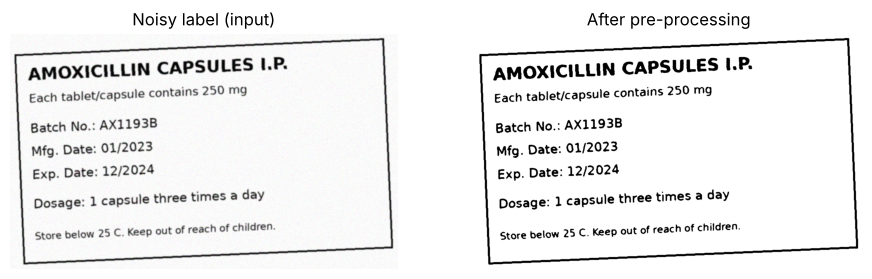

---- OCR text ----
AMOXICILLIN CAPSULES I.P.
Each tablet/capsule contains 250 mg

Batch No.: AX1193B

Mfg. Date: 01/2023

Exp. Date: 12/2024

Dosage: 1 capsule three times a day
Store below 25 C. Keep out of reach of children.



In [3]:
def preprocess(path):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)   # bigger text reads better
    gray = cv2.medianBlur(gray, 3)                                              # remove speckle noise
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return img, binary

def read_label(path):
    original, binary = preprocess(path)
    text = pytesseract.image_to_string(binary, config="--psm 6")
    return original, binary, text

orig, binary, text = read_label("labels/label_2.png")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)); ax[0].set_title("Noisy label (input)"); ax[0].axis("off")
ax[1].imshow(binary, cmap="gray");                    ax[1].set_title("After pre-processing"); ax[1].axis("off")
plt.show()
print("---- OCR text ----")
print(text)

### A3. Interpret: extract the useful fields with regular expressions

In [4]:
def extract_fields(text):
    lines = [l.strip() for l in text.splitlines() if l.strip()]
    def find(pattern):
        m = re.search(pattern, text, re.I)
        return m.group(1).strip() if m else None
    return {
        "drug":     lines[0] if lines else None,
        "strength": (lambda m: f"{m.group(1)} {m.group(2).lower()}" if m else None)(
                        re.search(r"(\d+(?:\.\d+)?)\s*(mg|mcg|ml|g)\b", text, re.I)),
        "batch":    find(r"batch\s*no\.?\s*[:\-]?\s*([A-Z0-9]+)"),
        "mfg":      find(r"mfg\.?\s*date\s*[:\-]?\s*(\d{2}/\d{4})"),
        "exp":      find(r"exp\.?\s*date\s*[:\-]?\s*(\d{2}/\d{4})"),
        "dosage":   find(r"dosage\s*[:\-]?\s*(.+)"),
    }

def expiry_status(exp, today=None):
    if not exp:
        return "UNKNOWN (expiry not found)"
    today = today or datetime.date.today()
    month, year = map(int, exp.split("/"))
    return "EXPIRED" if (year, month) < (today.year, today.month) else "valid"

print(extract_fields(text))

{'drug': 'AMOXICILLIN CAPSULES I.P.', 'strength': '250 mg', 'batch': 'AX1193B', 'mfg': '01/2023', 'exp': '12/2024', 'dosage': '1 capsule three times a day'}


### A4. Decide / respond: the assistant's message

In [5]:
def assistant_message(f):
    status = expiry_status(f["exp"])
    msg = f"This looks like {f['drug']} ({f['strength']}). Label dosage: {f['dosage']}. "
    msg += f"Expiry {f['exp']} -> {status}. "
    if status == "EXPIRED":
        msg += "Do NOT use it; please ask a pharmacist how to dispose of it safely."
    elif status.startswith("UNKNOWN"):
        msg += "I could not read the expiry date, so please check the bottle yourself."
    else:
        msg += "Follow the dosage printed on the label or your doctor's advice."
    return msg

rows = []
for fname in sorted(os.listdir("labels")):
    _, _, txt = read_label(os.path.join("labels", fname))
    f = extract_fields(txt)
    f["file"] = fname
    rows.append(f)
    print(f"[{fname}] {assistant_message(f)}\n")
results = pd.DataFrame(rows).set_index("file")
results

[label_1.png] This looks like PARACETAMOL TABLETS I.P. (500 mg). Label dosage: 1 tablet every 6 hours after food. Expiry 02/2028 -> valid. Follow the dosage printed on the label or your doctor's advice.



[label_2.png] This looks like AMOXICILLIN CAPSULES I.P. (250 mg). Label dosage: 1 capsule three times a day. Expiry 12/2024 -> EXPIRED. Do NOT use it; please ask a pharmacist how to dispose of it safely.



[label_3.png] This looks like CETIRIZINE TABLETS I.P. (10 mg). Label dosage: 1] tablet at night. Expiry 05/2027 -> valid. Follow the dosage printed on the label or your doctor's advice.



,drug,strength,batch,mfg,exp,dosage
file,,,,,,
label_1.png,PARACETAMOL TABLETS I.P.,500 mg,PT2407A,03/2025,02/2028,1 tablet every 6 hours after food
label_2.png,AMOXICILLIN CAPSULES I.P.,250 mg,AX1193B,01/2023,12/2024,1 capsule three times a day
label_3.png,CETIRIZINE TABLETS I.P.,10 mg,CZ5521C,06/2025,05/2027,1] tablet at night


### A5. Evaluate field-extraction accuracy (against the known ground truth)

In [6]:
truth = pd.DataFrame(SAMPLES).set_index("file")
truth["drug"] = truth["drug"]; truth["strength"] = truth["strength"]
fields = ["drug", "strength", "batch", "mfg", "exp", "dosage"]

def norm(v):
    return re.sub(r"\s+", " ", str(v)).strip().lower()

correct = pd.DataFrame({fld: [norm(results.loc[i, fld]) == norm(truth.loc[i, fld]) for i in truth.index]
                        for fld in fields}, index=truth.index)
print(correct)
print("\nField accuracy        :", correct.mean().round(2).to_dict())
print("Overall accuracy      : %.1f %%" % (100 * correct.values.mean()))

             drug  strength  batch   mfg   exp  dosage
file                                                  
label_1.png  True      True   True  True  True    True
label_2.png  True      True   True  True  True    True
label_3.png  True      True   True  True  True   False

Field accuracy        : {'drug': 1.0, 'strength': 1.0, 'batch': 1.0, 'mfg': 1.0, 'exp': 1.0, 'dosage': 0.67}
Overall accuracy      : 94.4 %


*Limits:* tesseract works best on flat, well-lit, high-resolution labels. Curved bottles, glare or tiny print need better pre-processing or a trained detector (for instance the LandingLens model above, to crop the expiry/dosage region before OCR). The assistant only reads what is printed; it does not give medical advice.

# Part B — Emotion-aware cognitive assistant (facial expression detection)

**Perceive:** a pre-trained facial-expression model (DeepFace) gives a probability for each of seven emotions. **Interpret:** a short sliding window of frames smooths out one-frame errors. **Respond:** the assistant adapts its message. Run the DeepFace cells in Colab with a photo of your own face (or any dataset image), they need to download model weights.

In [ ]:
!pip -q install deepface tf-keras opencv-python-headless

In [ ]:
from deepface import DeepFace
import cv2
import matplotlib.pyplot as plt

IMAGE_PATH = "face.jpg"      # upload a photo (Colab: left panel > Files) or point to a dataset image

def detect_emotions(image_path):
    """Return (emotion_scores_dict, face_box) for the largest face in the image."""
    result = DeepFace.analyze(img_path=image_path, actions=["emotion"], enforce_detection=False)
    if isinstance(result, list):                        # newer DeepFace versions return a list of faces
        result = max(result, key=lambda r: r["region"]["w"] * r["region"]["h"])
    return result["emotion"], result["region"]

scores, box = detect_emotions(IMAGE_PATH)
img = cv2.cvtColor(cv2.imread(IMAGE_PATH), cv2.COLOR_BGR2RGB)
cv2.rectangle(img, (box["x"], box["y"]), (box["x"] + box["w"], box["y"] + box["h"]), (0, 255, 0), 3)
plt.imshow(img); plt.axis("off"); plt.title(max(scores, key=scores.get)); plt.show()
print({k: round(v, 1) for k, v in scores.items()})

### B1. Interpret and respond (runs without a camera)
The decision logic below takes any dictionary of emotion scores, so it can be tested with the output of `detect_emotions`, or, as here, with *simulated* scores.

In [7]:
from collections import Counter, deque

NEGATIVE = {"angry", "fear", "sad", "disgust"}

RESPONSES = {
    "happy":    "You look happy! Great, shall we continue with your tasks?",
    "neutral":  "How can I help you today?",
    "surprise": "That looked surprising. Would you like me to explain what happened?",
    "sad":      "You seem a little down. I can slow down, or we can take a short break.",
    "angry":    "I sense some frustration. Let me simplify things; tell me what is going wrong.",
    "fear":     "You seem worried. We can go step by step, there is no rush.",
    "disgust":  "Something seems off. Do you want me to show a different option?",
}

def dominant_emotion(scores):
    return max(scores, key=scores.get)

class EmotionTracker:
    """Smooths per-frame predictions over a sliding window and decides how the assistant responds."""
    def __init__(self, window=5):
        self.history = deque(maxlen=window)

    def update(self, scores):
        self.history.append(dominant_emotion(scores))
        smoothed = Counter(self.history).most_common(1)[0][0]
        negative_share = sum(e in NEGATIVE for e in self.history) / len(self.history)
        message = RESPONSES[smoothed]
        if negative_share >= 0.6 and len(self.history) >= 3:
            message += " (You have seemed stressed for a while; consider a short break or talking to someone you trust.)"
        return smoothed, message

def fake(**kw):
    s = {e: 1.0 for e in RESPONSES}
    s.update(kw)
    return s

# Simulated frame-by-frame scores (NOT real model output) to test the logic
frames = [fake(neutral=70), fake(neutral=60), fake(sad=65), fake(sad=72), fake(angry=55), fake(sad=80)]
tracker = EmotionTracker(window=5)
for i, f in enumerate(frames, 1):
    emotion, msg = tracker.update(f)
    print(f"frame {i}: raw={dominant_emotion(f):8s} smoothed={emotion:8s} -> {msg}")

frame 1: raw=neutral  smoothed=neutral  -> How can I help you today?
frame 2: raw=neutral  smoothed=neutral  -> How can I help you today?
frame 3: raw=sad      smoothed=neutral  -> How can I help you today?
frame 4: raw=sad      smoothed=neutral  -> How can I help you today?
frame 5: raw=angry    smoothed=neutral  -> How can I help you today? (You have seemed stressed for a while; consider a short break or talking to someone you trust.)
frame 6: raw=sad      smoothed=sad      -> You seem a little down. I can slow down, or we can take a short break. (You have seemed stressed for a while; consider a short break or talking to someone you trust.)


### Notes
- Facial-expression models are trained on posed or limited datasets and make mistakes, especially across different faces, lighting and cultures; the assistant treats the emotion as a hint and always lets the user correct it.
- Use only with the person's consent; faces are sensitive personal data and images should not be stored without need.
- Possible extension: fine-tune or replace DeepFace with a LandingLens classification model trained on your own labelled emotion dataset and call it from `detect_emotions`.